# Cập nhật trọng số trong Gradient Descent

*Bài 5, mục 5.1.3.* Quy tắc cập nhật: $x_{t+1} = x_t - \eta f'(x_t)$ (một biến), $\mathbf{w}_{t+1} = \mathbf{w}_t - \eta\nabla\mathcal{L}(\mathbf{w}_t)$ (nhiều biến).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Tính tay với $f(x) = x^2 + 4x + 4$

$f'(x) = 2x + 4$, $x_0 = 0$, $\eta = 0.25$. Cực tiểu tại $x^* = -2$.

In [2]:
x = 0.0
for t in range(4):
    g = 2 * x + 4
    x_moi = x - 0.25 * g                     # x_{t+1} = x_t - eta * f'(x_t)
    print("t = %d: x = %7.4f, f'(x) = %6.3f -> x mới = %7.4f, f = %.4f"
          % (t, x, g, x_moi, (x_moi + 2)**2))
    x = x_moi

t = 0: x =  0.0000, f'(x) =  4.000 -> x mới = -1.0000, f = 1.0000
t = 1: x = -1.0000, f'(x) =  2.000 -> x mới = -1.5000, f = 0.2500
t = 2: x = -1.5000, f'(x) =  1.000 -> x mới = -1.7500, f = 0.0625
t = 3: x = -1.7500, f'(x) =  0.500 -> x mới = -1.8750, f = 0.0156


## 2. Một bước GD cho hàm mất mát MSE

Dữ liệu 3 điểm ở notebook 01, $\eta = 0.1$. Mọi tham số được cập nhật **đồng thời**.

In [3]:
X = np.array([[1, 1], [1, 2], [1, 3]], dtype=float)
y = np.array([2, 3, 5], dtype=float)
loss = lambda w: np.sum((X @ w - y)**2) / (2 * len(y))

w = np.zeros(2)
g = X.T @ (X @ w - y) / len(y)
w_moi = w - 0.1 * g
print('w = %s, L = %.3f  ->  w = %s, L = %.3f' % (w, loss(w), w_moi.round(3), loss(w_moi)))

w = [0. 0.], L = 6.333  ->  w = [0.333 0.767], L = 1.283


## 3. Hàm $f(x) = x^2 + 5\sin x$

$f'(x) = 2x + 5\cos x = 0$ không giải được bằng công thức, dùng GD với hai điểm khởi tạo. Thuật toán dừng khi $|f'(x)| < 10^{-3}$.

x0 = -5: x = -1.1106, f(x) = -3.2464, sau 12 vòng lặp
x0 =  5: x = -1.1105, f(x) = -3.2464, sau 30 vòng lặp


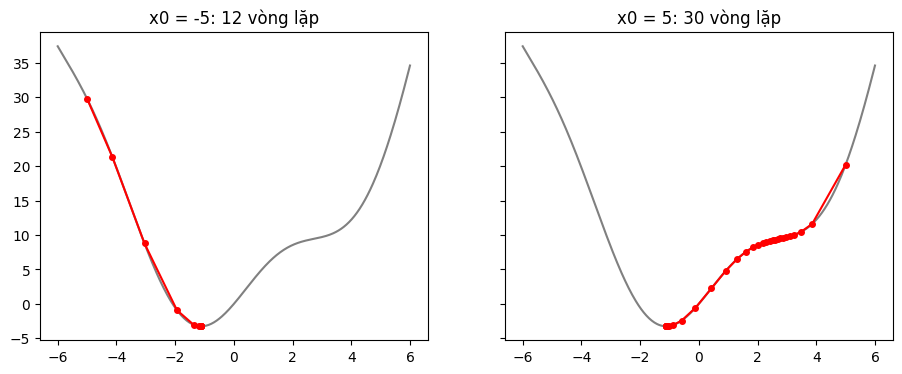

In [4]:
def f(x):
    return x**2 + 5 * np.sin(x)


def grad(x):
    return 2 * x + 5 * np.cos(x)


def gd_mot_bien(x0, eta, max_iter=100, tol=1e-3):
    x = x0
    lich_su = [x0]
    for t in range(max_iter):
        x = x - eta * grad(x)        # x_{t+1} = x_t - eta * f'(x_t)
        lich_su.append(x)
        if abs(grad(x)) < tol:       # đạo hàm đủ nhỏ -> dừng
            break
    return np.array(lich_su)


xs = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, x0 in zip(axes, [-5, 5]):
    h = gd_mot_bien(x0, eta=0.1)
    print('x0 = %2d: x = %.4f, f(x) = %.4f, sau %d vòng lặp' % (x0, h[-1], f(h[-1]), len(h) - 1))
    ax.plot(xs, f(xs), color='gray')
    ax.plot(h, f(h), 'ro-', ms=4)
    ax.set_title('x0 = %d: %d vòng lặp' % (x0, len(h) - 1))
plt.show()

Từ $x_0 = 5$ thuật toán chậm hơn vì phải đi qua vùng gần như bằng phẳng quanh $x \approx 2.5$ (đạo hàm nhỏ nên bước đi ngắn).